# Assigment 1 - Part 2

Imports

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.datasets import STL10
import torchvision.transforms as tt
from torchvision.models import resnet18, mobilenet_v3_large
from torchvision.models import ResNet18_Weights, MobileNet_V3_Large_Weights
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

torch.manual_seed(42)
np.random.seed(42)

STL-10 dataset download and preparation

In [ ]:
  # Resize to 224 to match ImageNet-pretrained input size
transform = tt.Compose([
    tt.Resize(224),
    tt.ToTensor(),
    tt.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

training_data = STL10(root='./data', split='train', download=True, transform=transform)
testing_data = STL10(root='./data', split='test', download=True, transform=transform)

# Train/validation split (80/20)
train_size = int(len(training_data) * 0.8)
val_size = len(training_data) - train_size
train_set, val_set = torch.utils.data.random_split(
    training_data, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)

batch_size = 64
train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader = torch.utils.data.DataLoader(val_set, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
test_loader = torch.utils.data.DataLoader(testing_data, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
categories = training_data.classes
print(f'Device: {device}')
print(f'Train samples: {len(train_set)}, Val samples: {len(val_set)}, Test samples: {len(testing_data)}')

Device: cuda
Train samples: 4000, Val samples: 1000, Test samples: 8000


Training and Evaluation functions

In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10):
    train_losses, val_losses, val_accuracies = [], [], []

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)

        epoch_train_loss = running_loss / len(train_loader.dataset)
        train_losses.append(epoch_train_loss)

        model.eval()
        running_val_loss = 0.0
        correct = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                running_val_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                correct += (preds == labels).sum().item()

        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_acc = 100.0 * correct / len(val_loader.dataset)
        val_losses.append(epoch_val_loss)
        val_accuracies.append(epoch_val_acc)

        print(f'Epoch [{epoch+1}/{num_epochs}] Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}%')

    return train_losses, val_losses, val_accuracies

def evaluate_model(model, test_loader, categories, model_name='Model'):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    cm = confusion_matrix(all_labels, all_preds)
    class_acc = cm.diagonal() / cm.sum(axis=1)
    mca = 100.0 * np.mean(class_acc)
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro')

    print(f'=== {model_name} Test Results ===')
    print(f'mean-Class Accuracy (mCA): {mca:.2f}%')
    print(f'Macro Precision: {precision*100:.2f}%')
    print(f'Macro Recall: {recall*100:.2f}%')
    print(f'Macro F1-Score: {f1*100:.2f}%')

    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=categories, yticklabels=categories)
    plt.title(f'{model_name} - Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

    return {'mCA': mca, 'Precision': precision * 100, 'Recall': recall * 100, 'F1': f1 * 100}

def plot_training_history(train_losses, val_losses, val_accs, title='Model'):
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss')
    plt.plot(val_losses, label='Val Loss')
    plt.title(f'{title} - Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(val_accs, label='Val Accuracy', color='green')
    plt.title(f'{title} - Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.tight_layout()
    plt.show()

Hyperparameters

In [ ]:
lr = 1e-4
num_epochs = 20
criterion = nn.CrossEntropyLoss()

ResNet-18 training from scratch

Epoch [1/20] Train Loss: 1.7566 | Val Loss: 1.6384 | Val Acc: 36.80%
Epoch [2/20] Train Loss: 1.3699 | Val Loss: 1.4755 | Val Acc: 46.30%
Epoch [3/20] Train Loss: 1.1166 | Val Loss: 1.7514 | Val Acc: 41.90%
Epoch [4/20] Train Loss: 0.8299 | Val Loss: 1.7464 | Val Acc: 44.10%
Epoch [5/20] Train Loss: 0.5181 | Val Loss: 2.0013 | Val Acc: 43.30%
Epoch [6/20] Train Loss: 0.2454 | Val Loss: 1.6128 | Val Acc: 49.70%
Epoch [7/20] Train Loss: 0.0876 | Val Loss: 1.7783 | Val Acc: 47.50%
Epoch [8/20] Train Loss: 0.0385 | Val Loss: 1.5329 | Val Acc: 52.40%
Epoch [9/20] Train Loss: 0.0201 | Val Loss: 1.4595 | Val Acc: 53.70%
Epoch [10/20] Train Loss: 0.0108 | Val Loss: 1.5392 | Val Acc: 52.90%
Epoch [11/20] Train Loss: 0.0090 | Val Loss: 1.4691 | Val Acc: 54.10%
Epoch [12/20] Train Loss: 0.0066 | Val Loss: 1.5361 | Val Acc: 53.80%
Epoch [13/20] Train Loss: 0.0058 | Val Loss: 1.4718 | Val Acc: 54.00%
Epoch [14/20] Train Loss: 0.0046 | Val Loss: 1.4517 | Val Acc: 55.60%
Epoch [15/20] Train Loss: 0.0

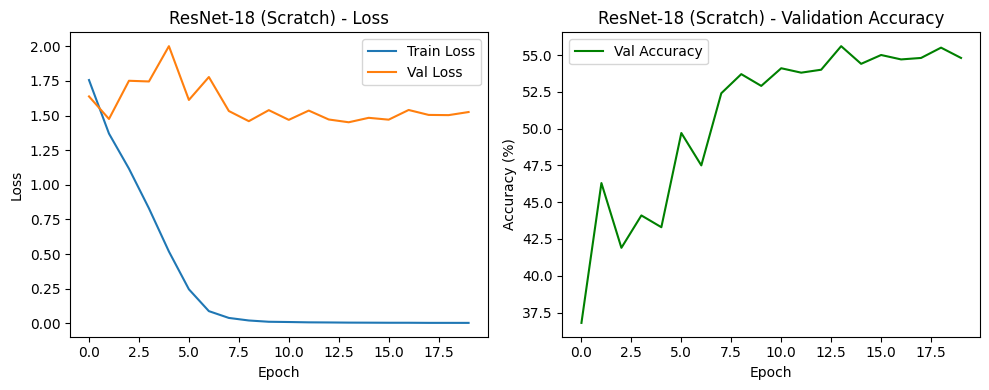

=== ResNet-18 (Scratch) Test Results ===
mean-Class Accuracy (mCA): 56.89%
Macro Precision: 56.93%
Macro Recall: 56.89%
Macro F1-Score: 56.70%


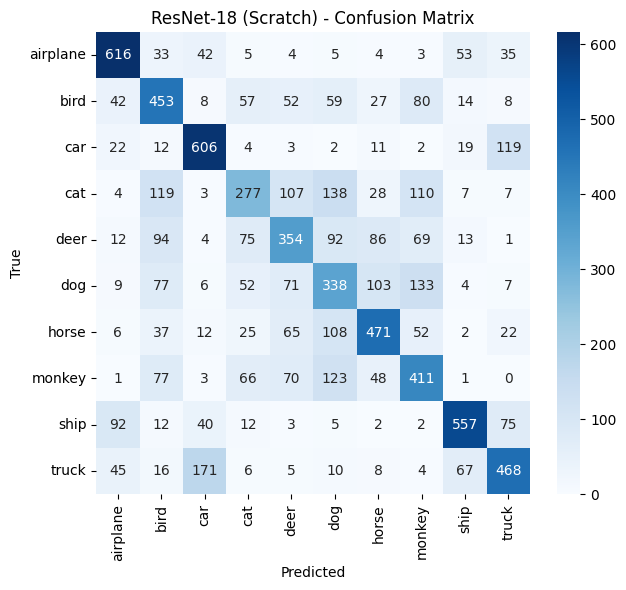

In [ ]:
resnet_scratch = resnet18(weights=None, num_classes=10).to(device)
optimizer_resnet_scratch = optim.Adam(resnet_scratch.parameters(), lr=lr, weight_decay=1e-4)

t_loss, v_loss, v_acc = train_model(resnet_scratch, train_loader, val_loader, criterion, optimizer_resnet_scratch, num_epochs=num_epochs)
plot_training_history(t_loss, v_loss, v_acc, title='ResNet-18 (Scratch)')
metrics_resnet_scratch = evaluate_model(resnet_scratch, test_loader, categories, model_name='ResNet-18 (Scratch)')

MobileNetV3 Large training from scratch

Epoch [1/20] Train Loss: 2.1231 | Val Loss: 2.3062 | Val Acc: 10.10%
Epoch [2/20] Train Loss: 1.7219 | Val Loss: 2.3160 | Val Acc: 8.60%
Epoch [3/20] Train Loss: 1.5663 | Val Loss: 2.3392 | Val Acc: 9.10%
Epoch [4/20] Train Loss: 1.4608 | Val Loss: 2.3787 | Val Acc: 9.10%
Epoch [5/20] Train Loss: 1.3155 | Val Loss: 2.4602 | Val Acc: 9.10%
Epoch [6/20] Train Loss: 1.1918 | Val Loss: 2.5859 | Val Acc: 10.10%
Epoch [7/20] Train Loss: 1.0544 | Val Loss: 2.7940 | Val Acc: 9.10%
Epoch [8/20] Train Loss: 0.9408 | Val Loss: 3.1002 | Val Acc: 10.40%
Epoch [9/20] Train Loss: 0.8148 | Val Loss: 3.1964 | Val Acc: 12.10%
Epoch [10/20] Train Loss: 0.7607 | Val Loss: 2.7799 | Val Acc: 11.70%
Epoch [11/20] Train Loss: 0.6736 | Val Loss: 2.8365 | Val Acc: 15.10%
Epoch [12/20] Train Loss: 0.5900 | Val Loss: 2.2914 | Val Acc: 28.10%
Epoch [13/20] Train Loss: 0.4933 | Val Loss: 2.4405 | Val Acc: 33.10%
Epoch [14/20] Train Loss: 0.4379 | Val Loss: 2.6409 | Val Acc: 36.10%
Epoch [15/20] Train Loss: 0.3553 |

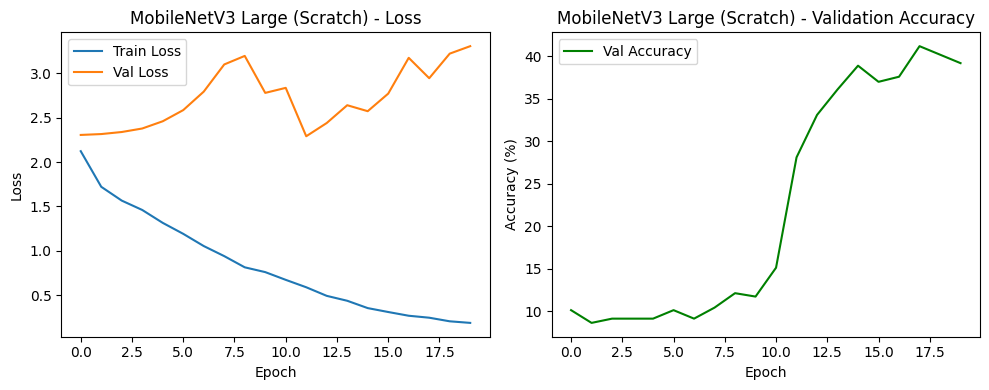

=== MobileNetV3 Large (Scratch) Test Results ===
mean-Class Accuracy (mCA): 39.17%
Macro Precision: 40.60%
Macro Recall: 39.17%
Macro F1-Score: 38.83%


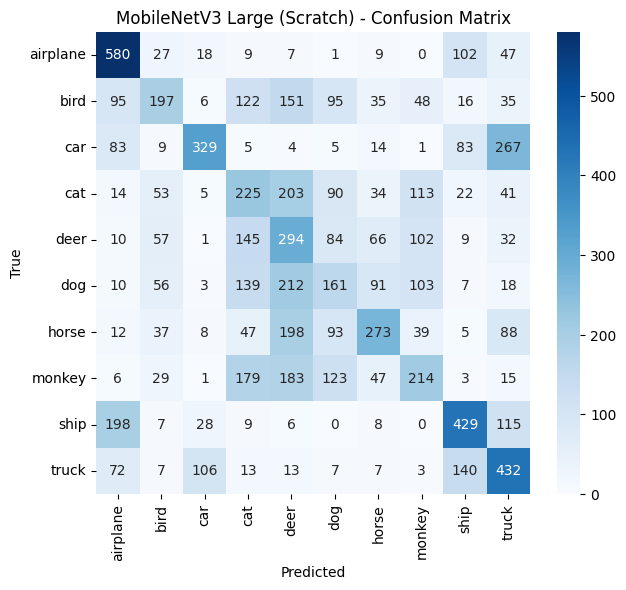

In [ ]:
mobilenet_scratch = mobilenet_v3_large(weights=None, num_classes=10).to(device)
optimizer_mobilenet_scratch = optim.Adam(mobilenet_scratch.parameters(), lr=lr, weight_decay=1e-4)

t_loss, v_loss, v_acc = train_model(mobilenet_scratch, train_loader, val_loader, criterion, optimizer_mobilenet_scratch, num_epochs=num_epochs)
plot_training_history(t_loss, v_loss, v_acc, title='MobileNetV3 Large (Scratch)')
metrics_mobilenet_scratch = evaluate_model(mobilenet_scratch, test_loader, categories, model_name='MobileNetV3 Large (Scratch)')

ResNet-18 training with pre-trained weights

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 106MB/s]


Epoch [1/20] Train Loss: 0.5609 | Val Loss: 0.2352 | Val Acc: 93.10%
Epoch [2/20] Train Loss: 0.0771 | Val Loss: 0.1871 | Val Acc: 94.20%
Epoch [3/20] Train Loss: 0.0207 | Val Loss: 0.1727 | Val Acc: 94.90%
Epoch [4/20] Train Loss: 0.0094 | Val Loss: 0.1582 | Val Acc: 95.20%
Epoch [5/20] Train Loss: 0.0061 | Val Loss: 0.1644 | Val Acc: 94.90%
Epoch [6/20] Train Loss: 0.0041 | Val Loss: 0.1695 | Val Acc: 94.80%
Epoch [7/20] Train Loss: 0.0033 | Val Loss: 0.1630 | Val Acc: 95.00%
Epoch [8/20] Train Loss: 0.0028 | Val Loss: 0.1723 | Val Acc: 94.70%
Epoch [9/20] Train Loss: 0.0019 | Val Loss: 0.1653 | Val Acc: 94.50%
Epoch [10/20] Train Loss: 0.0019 | Val Loss: 0.1668 | Val Acc: 95.10%
Epoch [11/20] Train Loss: 0.0015 | Val Loss: 0.1721 | Val Acc: 94.90%
Epoch [12/20] Train Loss: 0.0012 | Val Loss: 0.1672 | Val Acc: 94.70%
Epoch [13/20] Train Loss: 0.0013 | Val Loss: 0.1675 | Val Acc: 94.70%
Epoch [14/20] Train Loss: 0.0010 | Val Loss: 0.1753 | Val Acc: 94.60%
Epoch [15/20] Train Loss: 0.0

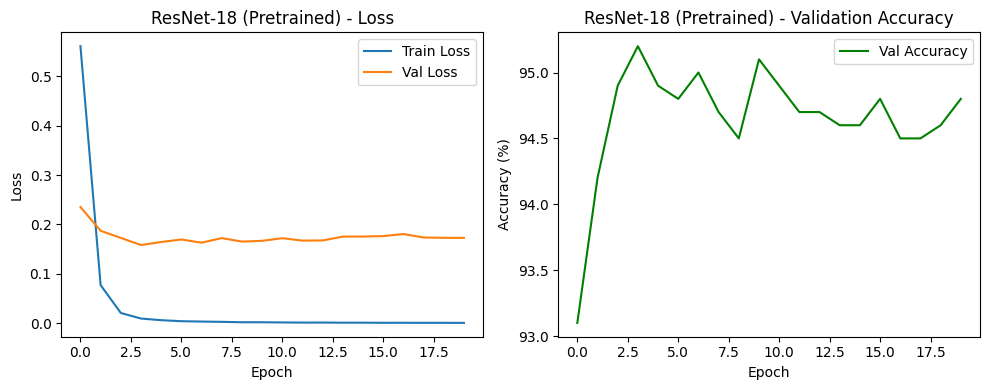

=== ResNet-18 (Pretrained) Test Results ===
mean-Class Accuracy (mCA): 95.41%
Macro Precision: 95.41%
Macro Recall: 95.41%
Macro F1-Score: 95.40%


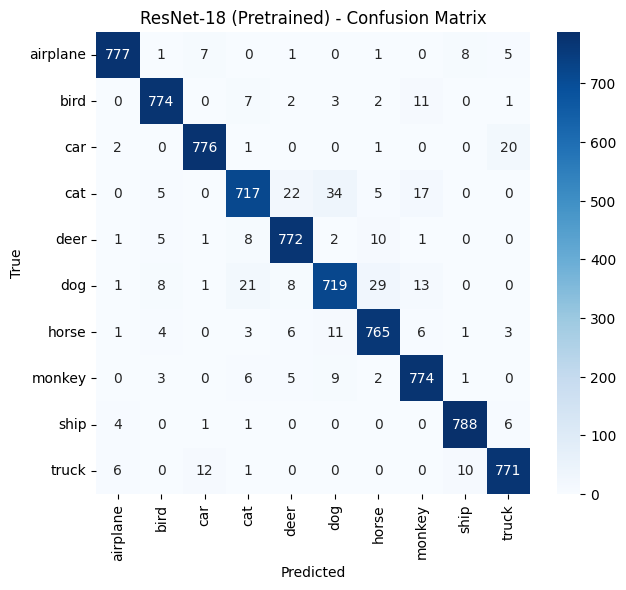

In [ ]:
resnet_pretrained = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
resnet_pretrained.fc = nn.Linear(resnet_pretrained.fc.in_features, 10)
resnet_pretrained = resnet_pretrained.to(device)

optimizer_resnet_pt = optim.Adam(resnet_pretrained.parameters(), lr=lr, weight_decay=1e-4)
t_loss, v_loss, v_acc = train_model(resnet_pretrained, train_loader, val_loader, criterion, optimizer_resnet_pt, num_epochs=num_epochs)
plot_training_history(t_loss, v_loss, v_acc, title='ResNet-18 (Pretrained)')
metrics_resnet_pt = evaluate_model(resnet_pretrained, test_loader, categories, model_name='ResNet-18 (Pretrained)')

MobileNetV3 Large training with pre-trained weights

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 86.4MB/s]


Epoch [1/20] Train Loss: 1.0318 | Val Loss: 0.3436 | Val Acc: 89.50%
Epoch [2/20] Train Loss: 0.2061 | Val Loss: 0.2028 | Val Acc: 94.00%
Epoch [3/20] Train Loss: 0.0790 | Val Loss: 0.1760 | Val Acc: 94.60%
Epoch [4/20] Train Loss: 0.0326 | Val Loss: 0.1572 | Val Acc: 94.70%
Epoch [5/20] Train Loss: 0.0173 | Val Loss: 0.1501 | Val Acc: 94.90%
Epoch [6/20] Train Loss: 0.0108 | Val Loss: 0.1506 | Val Acc: 94.90%
Epoch [7/20] Train Loss: 0.0074 | Val Loss: 0.1441 | Val Acc: 95.40%
Epoch [8/20] Train Loss: 0.0047 | Val Loss: 0.1486 | Val Acc: 95.60%
Epoch [9/20] Train Loss: 0.0038 | Val Loss: 0.1427 | Val Acc: 95.50%
Epoch [10/20] Train Loss: 0.0026 | Val Loss: 0.1513 | Val Acc: 95.40%
Epoch [11/20] Train Loss: 0.0027 | Val Loss: 0.1585 | Val Acc: 95.30%
Epoch [12/20] Train Loss: 0.0015 | Val Loss: 0.1582 | Val Acc: 95.30%
Epoch [13/20] Train Loss: 0.0016 | Val Loss: 0.1614 | Val Acc: 95.10%
Epoch [14/20] Train Loss: 0.0012 | Val Loss: 0.1663 | Val Acc: 94.90%
Epoch [15/20] Train Loss: 0.0

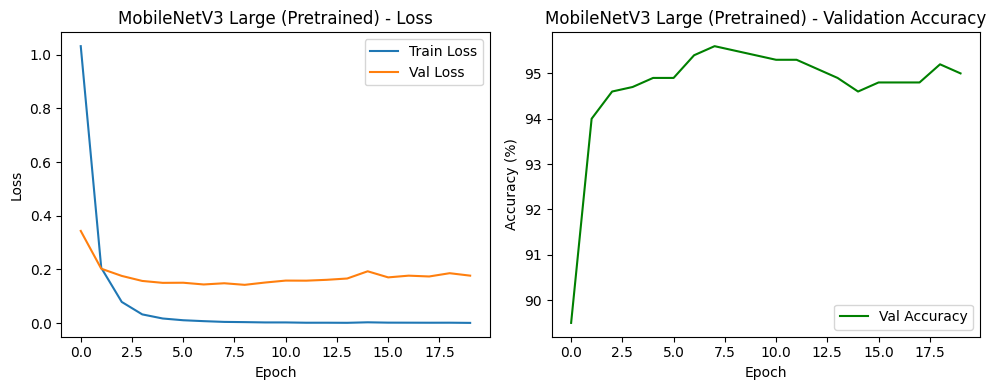

=== MobileNetV3 Large (Pretrained) Test Results ===
mean-Class Accuracy (mCA): 95.72%
Macro Precision: 95.73%
Macro Recall: 95.72%
Macro F1-Score: 95.72%


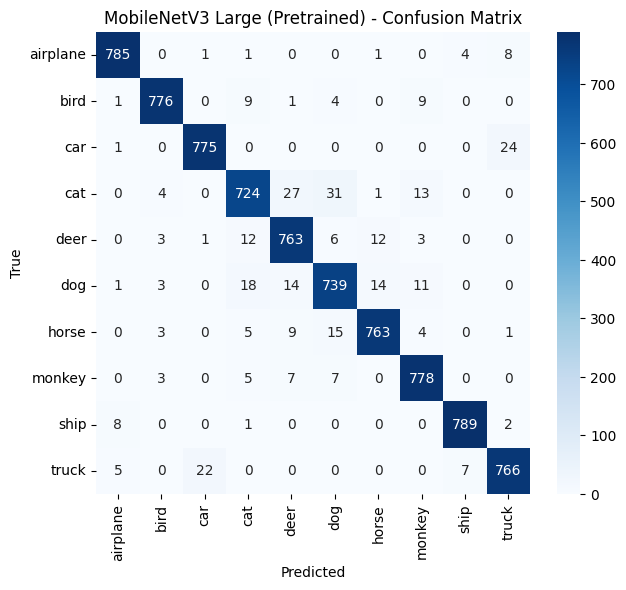

In [ ]:
mobilenet_pretrained = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.IMAGENET1K_V1)
mobilenet_pretrained.classifier[3] = nn.Linear(mobilenet_pretrained.classifier[3].in_features, 10)
mobilenet_pretrained = mobilenet_pretrained.to(device)

optimizer_mobilenet_pt = optim.Adam(mobilenet_pretrained.parameters(), lr=lr, weight_decay=1e-4)
t_loss, v_loss, v_acc = train_model(mobilenet_pretrained, train_loader, val_loader, criterion, optimizer_mobilenet_pt, num_epochs=num_epochs)
plot_training_history(t_loss, v_loss, v_acc, title='MobileNetV3 Large (Pretrained)')
metrics_mobilenet_pt = evaluate_model(mobilenet_pretrained, test_loader, categories, model_name='MobileNetV3 Large (Pretrained)')

# Middle Fusion

Epoch [1/20] Train Loss: 1.0509 | Val Loss: 0.4978 | Val Acc: 95.00%
Epoch [2/20] Train Loss: 0.1968 | Val Loss: 0.2745 | Val Acc: 96.00%
Epoch [3/20] Train Loss: 0.0867 | Val Loss: 0.2164 | Val Acc: 96.10%
Epoch [4/20] Train Loss: 0.0520 | Val Loss: 0.1897 | Val Acc: 96.00%
Epoch [5/20] Train Loss: 0.0368 | Val Loss: 0.1734 | Val Acc: 96.10%
Epoch [6/20] Train Loss: 0.0258 | Val Loss: 0.1641 | Val Acc: 96.10%
Epoch [7/20] Train Loss: 0.0205 | Val Loss: 0.1575 | Val Acc: 96.20%
Epoch [8/20] Train Loss: 0.0169 | Val Loss: 0.1531 | Val Acc: 96.10%
Epoch [9/20] Train Loss: 0.0141 | Val Loss: 0.1508 | Val Acc: 96.00%
Epoch [10/20] Train Loss: 0.0122 | Val Loss: 0.1460 | Val Acc: 96.20%
Epoch [11/20] Train Loss: 0.0103 | Val Loss: 0.1435 | Val Acc: 96.30%
Epoch [12/20] Train Loss: 0.0089 | Val Loss: 0.1398 | Val Acc: 96.30%
Epoch [13/20] Train Loss: 0.0082 | Val Loss: 0.1388 | Val Acc: 96.10%
Epoch [14/20] Train Loss: 0.0073 | Val Loss: 0.1379 | Val Acc: 96.20%
Epoch [15/20] Train Loss: 0.0

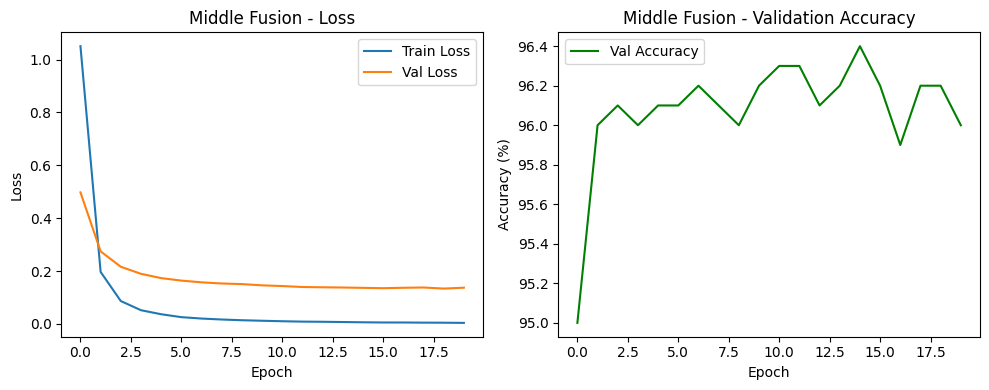

=== Middle Fusion Test Results ===
mean-Class Accuracy (mCA): 96.04%
Macro Precision: 96.03%
Macro Recall: 96.04%
Macro F1-Score: 96.03%


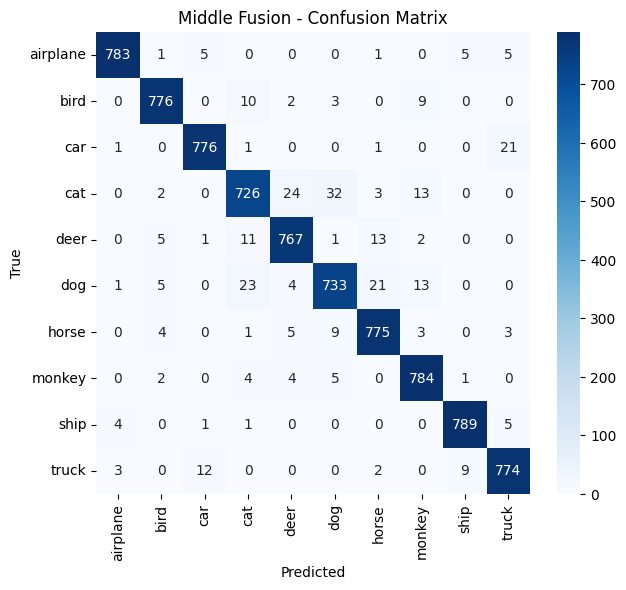

In [ ]:
class MiddleFusionNet(nn.Module):
    def __init__(self, resnet, mobilenet, num_classes=10):
        super().__init__()
        # Feature extractors (without final pooling and classifier)
        self.resnet_features = nn.Sequential(*list(resnet.children())[:-2])
        self.mobilenet_features = mobilenet.features

        # Freeze extractor weights
        for p in self.resnet_features.parameters():
            p.requires_grad = False
        for p in self.mobilenet_features.parameters():
            p.requires_grad = False

        # Concatenation fusion: 512 (ResNet) + 960 (MobileNetV3) = 1472 channels
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(1472, num_classes)
        )

    def forward(self, x):
        f1 = self.resnet_features(x)
        f2 = self.mobilenet_features(x)
        # Align spatial dims if needed
        if f1.shape[2:] != f2.shape[2:]:
            f1 = nn.functional.adaptive_avg_pool2d(f1, f2.shape[2:])
        f = torch.cat((f1, f2), dim=1)
        return self.classifier(f)

fusion_model = MiddleFusionNet(resnet_pretrained, mobilenet_pretrained, num_classes=10).to(device)
optimizer_fusion = optim.Adam(fusion_model.classifier.parameters(), lr=lr, weight_decay=1e-4)

t_loss, v_loss, v_acc = train_model(fusion_model, train_loader, val_loader, criterion, optimizer_fusion, num_epochs=num_epochs)
plot_training_history(t_loss, v_loss, v_acc, title='Middle Fusion')
metrics_fusion = evaluate_model(fusion_model, test_loader, categories, model_name='Middle Fusion')

Metrics comparison

In [ ]:
results = {
    'ResNet-18 (Scratch)': metrics_resnet_scratch,
    'MobileNetV3 (Scratch)': metrics_mobilenet_scratch,
    'ResNet-18 (Pretrained)': metrics_resnet_pt,
    'MobileNetV3 (Pretrained)': metrics_mobilenet_pt,
    'Middle Fusion': metrics_fusion
}
df_results = pd.DataFrame(results).T
print(df_results.round(2))

                            mCA  Precision  Recall     F1
ResNet-18 (Scratch)       56.89      56.93   56.89  56.70
MobileNetV3 (Scratch)     39.17      40.60   39.17  38.83
ResNet-18 (Pretrained)    95.41      95.41   95.41  95.40
MobileNetV3 (Pretrained)  95.72      95.73   95.72  95.72
Middle Fusion             96.04      96.03   96.04  96.03
